# Task 3 — CycleGAN: photo ↔ Monet (unpaired image-to-image translation)

**DATA 266 · Lab 1** · Two generators (G_AB: Monet→photo, G_BA: photo→Monet) and two PatchGAN
discriminators (D_A judges Monets, D_B judges photos) are trained from scratch with
**adversarial + cycle-consistency (+ identity) losses** (Zhu et al., 2017).
No pretrained image model generates or touches any output image. Inception-v3 / AlexNet appear only
inside the *metrics* (FID/KID/LPIPS).

Direction convention = the course's `Part3_Evaluation_Script.ipynb`: **A = Monet, B = photo**.
`pred_A2B/` = generated photos (Monet→photo, G_AB); `pred_B2A/` = generated Monets (photo→Monet, G_BA).
The Kaggle `submission.csv` (ID, FID, MiFID) is produced by running that official script unchanged.

Notebook map
1. Setup · 2. Data (unpaired domains, team-fixed held-out photos) · 3. Model · 4. Training (with resume)
5. Training-behaviour analysis (loss curves, D outputs, gradient norms, NaNs) · 6. Evaluation via `evaluate_local.py`
(FID, KID, precision/recall/density/coverage, cycle L1, LPIPS, content cosine — both directions)
7. Official evaluation script → Kaggle `submission.csv` · 8. results.md + manifest

In [1]:
MEMBER = "ruchika_chaurasia"   # <-- the only line that differs between member notebooks
TASK = "task3_gan"

import importlib.util, os, subprocess, sys
from pathlib import Path

# Optional extra run of this member's model, e.g. RUN=long100 -> reads config_long100.yaml and writes
# everything to task3_gan/<member>/runs/long100/ (the main run in task3_gan/<member>/ is never touched).
RUN = os.environ.get("RUN", "")

for pkg, mod in [("pyyaml", "yaml"), ("torchmetrics", "torchmetrics"), ("torch-fidelity", "torch_fidelity")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

def _find_root():
    if os.environ.get("REPO_ROOT"):
        return Path(os.environ["REPO_ROOT"]).resolve()
    here = Path.cwd().resolve()
    for q in [here, *here.parents]:
        if (q / "README.md").exists() and (q / "task1_llm").is_dir():
            return q
    raise FileNotFoundError("cd into the repo folder first (the one containing README.md)")

REPO_ROOT = _find_root()
MEMBER_DIR = REPO_ROOT / TASK / MEMBER
for p in [REPO_ROOT, REPO_ROOT / TASK / "common", MEMBER_DIR / "src", MEMBER_DIR]:
    sys.path.insert(0, str(p))

In [2]:
import json, math, random, time, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from common.runtime import (RawLogger, get_device, hardware_info, is_smoke, load_config, peak_memory_mb,
                            personal_params, reset_peak_memory, set_seed, write_manifest, file_sha)
import data_task3 as D
from cyclegan_models import build_models, count_params, ImagePool, DiffAugment
import evaluate_local as EV

CFG_PATH = MEMBER_DIR / (f"config_{RUN}.yaml" if RUN else "config.yaml")
CFG = load_config(CFG_PATH)
if CFG.get("sid4") is not None:
    PP = personal_params(int(CFG["sid4"]))
    SID4, SEED, SLICE, HP_ID, CLS_A, CLS_B = (PP[k] for k in ["SID4", "SEED", "SLICE", "HP_ID", "CLS_A", "CLS_B"])
    print(f"SID4={SID4}  SEED={SEED}  SLICE={SLICE}  HP_ID={HP_ID}  CLS_A={CLS_A}  CLS_B={CLS_B}")
SEED = int(CFG["seed"])

if is_smoke():
    CFG["data"].update(load_size=266, max_train_photos=40)
    CFG["model"].update(ngf=8, ndf=8, n_res_blocks=2)
    CFG["train"].update(epochs=2, decay_start_epoch=1, steps_per_epoch=3, log_every=1, resume=False)

TAG = MEMBER + (f"_{RUN}" if RUN else "")          # used in log / manifest names
RUN_DIR = (MEMBER_DIR / "runs" / RUN) if RUN else MEMBER_DIR
OUT_ROOT = (REPO_ROOT / "_smoke" / TASK / TAG) if is_smoke() else RUN_DIR
for sub in ["checkpoints", "outputs/progress", "outputs/figures", "data_processed"]:
    (OUT_ROOT / sub).mkdir(parents=True, exist_ok=True)

set_seed(SEED)
device = get_device()
log = RawLogger(REPO_ROOT, TASK, TAG)
HW = hardware_info()
log("member:", MEMBER, "| run:", RUN or "main", "| config:", CFG_PATH.name, "| lineup:", CFG.get("lineup"),
    "| seed:", SEED, "| smoke:", is_smoke())
log("hardware:", json.dumps(HW))
log("config:", json.dumps(CFG))

SID4=8283  SEED=8283  SLICE=283  HP_ID=3  CLS_A=3  CLS_B=4
raw log started: reproducibility/raw_logs/task3_gan_ruchika_chaurasia_long100_diffaug_20261002_011057.log
member: ruchika_chaurasia | run: long100_diffaug | config: config_long100_diffaug.yaml | lineup: A | seed: 8283 | smoke: False
hardware: {"cpu": "Intel(R) Core(TM) Ultra 9 285K", "cpu_count": 24, "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.31", "python": "3.10.13", "torch": "2.11.0+cu128", "cuda_available": true, "gpu": "NVIDIA GeForce RTX 5090", "gpu_memory_gb": 31.84, "cuda": "12.8", "cudnn": 91900}
config: {"member": "ruchika_chaurasia", "lineup": "A", "sid4": 8283, "seed": 8283, "data": {"photo_dir": "task3_gan/data/photo_jpg", "monet_dir": "task3_gan/data/monet_jpg", "image_size": 256, "load_size": 286, "max_train_photos": null}, "model": {"generator": "resnet", "ngf": 64, "n_res_blocks": 9, "ndf": 64, "d_layers": 3}, "train": {"gan_loss": "lsgan", "lambda_cycle": 10.0, "lambda_identity": 0.5

## Data — two unpaired domains
* **Domain A (Monet):** `task3_gan/data/monet_jpg/` (300 Monet paintings, 256×256)
* **Domain B (photos):** `task3_gan/data/photo_jpg/` (7,038 landscape photos, 256×256)

The pairing is **unpaired**: each step draws a random photo and a random painting.
500 photos (team-fixed list in `task3_gan/common/team_eval_split.json`) are **held out from training**
for evaluation and the human audit. With only 300 paintings, all Monets are used for training, which
is standard for this dataset. The report states this as a limitation for the A2B (Monet→photo) metrics,
whose inputs are training paintings.

Augmentation (as in the paper): resize to `load_size` then random `image_size` crop + horizontal flip.
All training images are pre-loaded into RAM as uint8, so the GPU is never waiting on disk.

/app/data266-lab1/task3_gan/common/data_task3.py:57: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  out[i] = torch.from_numpy(np.asarray(img)).permute(2, 0, 1)


Monet (A): 300 | train photos (B): 6,538 | held-out eval photos: 500 | audit photos: 30 | loaded in 52s


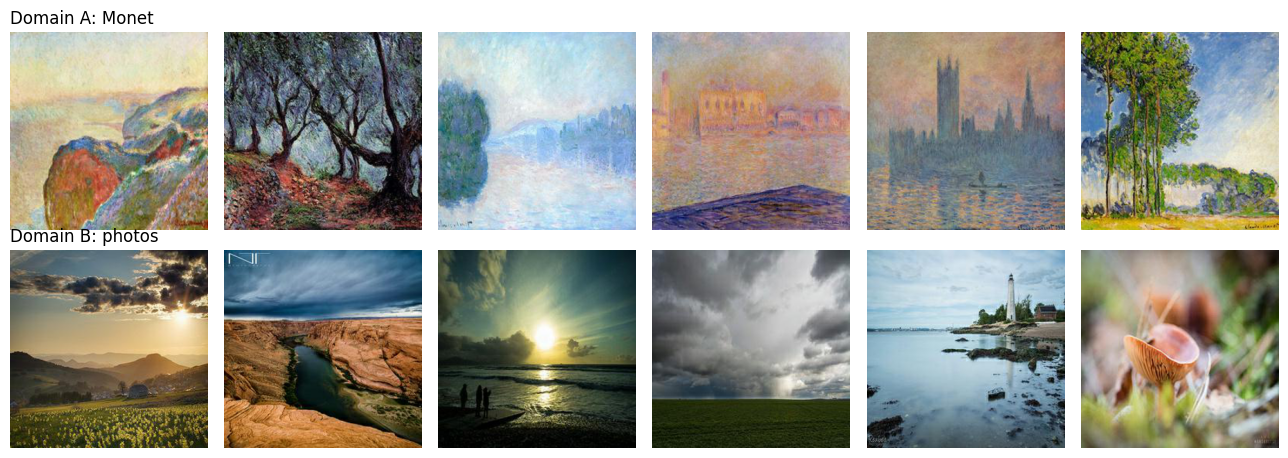

In [3]:
dc = CFG["data"]
scratch = Path(tempfile.gettempdir()) / "lab1_task3_data"
scratch.mkdir(exist_ok=True)
photo_dir = D.maybe_local_copy(REPO_ROOT / dc["photo_dir"], scratch)
monet_dir = D.maybe_local_copy(REPO_ROOT / dc["monet_dir"], scratch)
split = D.team_split(REPO_ROOT, REPO_ROOT / dc["photo_dir"])
held_out = set(split["eval_photos"])
train_photo_paths = [p for p in D.list_images(photo_dir) if p.name not in held_out]
if dc.get("max_train_photos"):
    train_photo_paths = train_photo_paths[: dc["max_train_photos"]]
monet_paths = D.list_images(monet_dir)
t0 = time.perf_counter()
train_A = D.load_uint8(monet_paths, dc["load_size"])          # domain A = Monet
train_B = D.load_uint8(train_photo_paths, dc["load_size"])    # domain B = photos (held-out photos excluded)
log(f"Monet (A): {len(train_A):,} | train photos (B): {len(train_B):,} | held-out eval photos: {len(held_out)} "
    f"| audit photos: {len(split['audit_photos'])} | loaded in {time.perf_counter() - t0:.0f}s")

fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
for j in range(6):
    ax[0, j].imshow(train_A[j].permute(1, 2, 0)); ax[0, j].axis("off")
    ax[1, j].imshow(train_B[j].permute(1, 2, 0)); ax[1, j].axis("off")
ax[0, 0].set_title("Domain A: Monet", loc="left"); ax[1, 0].set_title("Domain B: photos", loc="left")
plt.tight_layout(); plt.savefig(OUT_ROOT / "outputs" / "figures" / "domains.png", dpi=100); plt.show()

## Model
Architecture and loss settings come from `config.yaml` (see the justification in `results.md`).

In [4]:
MC, TC = CFG["model"], CFG["train"]
G_AB, G_BA, D_A, D_B = build_models(MC)
for m in (G_AB, G_BA, D_A, D_B):
    m.to(device)
PARAMS = {n: count_params(m) for n, m in [("G_AB", G_AB), ("G_BA", G_BA), ("D_A", D_A), ("D_B", D_B)]}
log("parameters:", json.dumps(PARAMS), "| total:", f"{sum(PARAMS.values()):,}")
with torch.no_grad():
    x = torch.zeros(1, 3, dc["image_size"], dc["image_size"], device=device)
    log(f"shape check: G_AB {tuple(G_AB(x).shape)} | D_B patch grid {tuple(D_B(x).shape)}")

parameters: {"G_AB": 11378179, "G_BA": 11378179, "D_A": 2764737, "D_B": 2764737} | total: 28,285,832
shape check: G_AB (1, 3, 256, 256) | D_B patch grid (1, 1, 30, 30)


## Losses and training loop
For a painting *a* and a photo *b*:
* **Adversarial:** G_BA tries to make D_A(G_BA(b)) look like a real Monet, and D_A tries to tell real paintings from fakes (same for G_AB / D_B with photos).
  `lsgan` uses mean-squared error on the patch outputs (the paper's choice; more stable gradients).
  `vanilla` uses binary cross-entropy.
* **Cycle consistency:** ‖G_BA(G_AB(a)) − a‖₁ + ‖G_AB(G_BA(b)) − b‖₁, weighted by λ_cyc. This forces the
  translation to keep the content, because otherwise it could not be undone.
* **Identity:** ‖G_AB(b) − b‖₁ + ‖G_BA(a) − a‖₁, weighted by λ_id·λ_cyc. This discourages unnecessary colour shifts.
* Discriminators see a **pool of 50 past fakes**. Adam with (β₁ = 0.5, β₂ = 0.999). Learning rate is
  constant, then decays linearly to 0 after `decay_start_epoch`.
* One "epoch" = `steps_per_epoch` random unpaired draws (the domains differ in size, so a fixed step
  budget is clearer than "passes").
* Logged every `log_every` steps: all loss terms, gradient norms of G and D, mean D outputs on real/fake,
  and NaN / AMP-overflow counts.

In [5]:
USE_AMP = bool(TC.get("amp", True)) and device.type == "cuda"
lam_c, lam_i = TC["lambda_cycle"], TC["lambda_identity"]
# DiffAugment (Zhao et al., 2020): the SAME random differentiable augmentation is applied to every image a
# discriminator sees, real or fake. With only 300 Monets this stops D from memorising the paintings.
POLICY = TC.get("diffaugment") or ""
AUG = (lambda x: DiffAugment(x, POLICY)) if POLICY else (lambda x: x)
log("DiffAugment policy:", POLICY or "none")
_nm = lambda a: float(np.nanmean(a)) if np.any(np.isfinite(a)) else float("nan")   # mean ignoring overflow steps

def gan_loss(pred, is_real):
    pred = pred.float()
    target = torch.ones_like(pred) if is_real else torch.zeros_like(pred)
    if TC["gan_loss"] == "lsgan":
        return F.mse_loss(pred, target)
    return F.binary_cross_entropy_with_logits(pred, target)

def set_grad(nets, flag):
    for n in nets:
        for p in n.parameters():
            p.requires_grad_(flag)

opt_G = torch.optim.Adam(list(G_AB.parameters()) + list(G_BA.parameters()), lr=TC["lr"], betas=(TC["beta1"], 0.999))
opt_D = torch.optim.Adam(list(D_A.parameters()) + list(D_B.parameters()), lr=TC["lr"], betas=(TC["beta1"], 0.999))
decay_len = TC["epochs"] - TC["decay_start_epoch"]
lr_rule = lambda e: 1.0 - max(0, e - TC["decay_start_epoch"]) / float(decay_len + 1)
sch_G = torch.optim.lr_scheduler.LambdaLR(opt_G, lr_rule)
sch_D = torch.optim.lr_scheduler.LambdaLR(opt_D, lr_rule)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
pool_A, pool_B = ImagePool(TC["pool_size"]), ImagePool(TC["pool_size"])

CK_LAST = OUT_ROOT / "checkpoints" / "last.pt"
state = {"epoch": 0, "step": 0, "log": [], "nan_count": 0, "amp_skips": 0, "train_seconds": 0.0}
if TC.get("resume", True) and CK_LAST.exists():
    ck = torch.load(CK_LAST, map_location=device, weights_only=False)
    for m, k in [(G_AB, "G_AB"), (G_BA, "G_BA"), (D_A, "D_A"), (D_B, "D_B")]:
        m.load_state_dict(ck[k])
    opt_G.load_state_dict(ck["opt_G"]); opt_D.load_state_dict(ck["opt_D"]); scaler.load_state_dict(ck["scaler"])
    sch_G.load_state_dict(ck["sch_G"]); sch_D.load_state_dict(ck["sch_D"]); state = ck["state"]
    log(f"RESUMED from last.pt at epoch {state['epoch']}")

fixed_A = D.to_m11(D.random_crop_flip(train_A[:4], dc["image_size"], torch.Generator().manual_seed(0))).to(device)   # Monets
fixed_B = D.to_m11(D.load_uint8([REPO_ROOT / dc["photo_dir"] / n for n in split["eval_photos"][:4]], dc["image_size"])).to(device)  # held-out photos

def progress_grid(epoch):
    G_AB.eval(); G_BA.eval()
    with torch.no_grad():
        fb, fa = G_AB(fixed_A).float(), G_BA(fixed_B).float()
    G_AB.train(); G_BA.train()
    EV.save_grid([fixed_A.cpu(), fb.cpu(), fixed_B.cpu(), fa.cpu()],
                 [f"epoch {epoch}: Monet", "G_AB -> photo", "photo", "G_BA -> Monet"],
                 OUT_ROOT / "outputs" / "progress" / f"epoch_{epoch:03d}.png")

def gnorm(params):
    return torch.nn.utils.clip_grad_norm_(params, TC.get("grad_clip") or float("inf")).item()

DiffAugment policy: color,translation,cutout


In [6]:
gen = torch.Generator().manual_seed(SEED)
bs = TC["batch_size"]
reset_peak_memory(device)
try:
    for epoch in range(state["epoch"], TC["epochs"]):
        G_AB.train(); G_BA.train(); D_A.train(); D_B.train()
        t0 = time.perf_counter()
        acc = {}
        for it in range(TC["steps_per_epoch"]):
            ia = torch.randint(0, len(train_A), (bs,), generator=gen)
            ib = torch.randint(0, len(train_B), (bs,), generator=gen)
            real_A = D.to_m11(D.random_crop_flip(train_A[ia], dc["image_size"], gen)).to(device, non_blocking=True)
            real_B = D.to_m11(D.random_crop_flip(train_B[ib], dc["image_size"], gen)).to(device, non_blocking=True)

            # ---------------- generators
            set_grad([D_A, D_B], False)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                fake_B = G_AB(real_A); rec_A = G_BA(fake_B)
                fake_A = G_BA(real_B); rec_B = G_AB(fake_A)
                l_adv_AB = gan_loss(D_B(AUG(fake_B)), True)
                l_adv_BA = gan_loss(D_A(AUG(fake_A)), True)
                l_cyc_A = F.l1_loss(rec_A.float(), real_A) * lam_c
                l_cyc_B = F.l1_loss(rec_B.float(), real_B) * lam_c
                if lam_i > 0:
                    l_idt_A = F.l1_loss(G_BA(real_A).float(), real_A) * lam_c * lam_i
                    l_idt_B = F.l1_loss(G_AB(real_B).float(), real_B) * lam_c * lam_i
                else:
                    l_idt_A = l_idt_B = torch.zeros((), device=device)
                loss_G = l_adv_AB + l_adv_BA + l_cyc_A + l_cyc_B + l_idt_A + l_idt_B
            opt_G.zero_grad(set_to_none=True)
            if not torch.isfinite(loss_G):
                state["nan_count"] += 1; log(f"  non-finite G loss at step {state['step']} - skipped"); continue
            scaler.scale(loss_G).backward()
            scaler.unscale_(opt_G)
            gn_G = gnorm(list(G_AB.parameters()) + list(G_BA.parameters()))
            if not math.isfinite(gn_G):          # fp16 overflow: GradScaler skips this step; don't let it poison the stats
                state["gn_nonfinite_G"] = state.get("gn_nonfinite_G", 0) + 1; gn_G = float("nan")
            scaler.step(opt_G)

            # ---------------- discriminators (on pooled, detached fakes)
            set_grad([D_A, D_B], True)
            fB, fA = pool_B.query(fake_B.detach()), pool_A.query(fake_A.detach())
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                pr_B, pf_B = D_B(AUG(real_B)), D_B(AUG(fB))
                pr_A, pf_A = D_A(AUG(real_A)), D_A(AUG(fA))
                l_D_B = 0.5 * (gan_loss(pr_B, True) + gan_loss(pf_B, False))
                l_D_A = 0.5 * (gan_loss(pr_A, True) + gan_loss(pf_A, False))
                loss_D = l_D_A + l_D_B
            opt_D.zero_grad(set_to_none=True)
            if not torch.isfinite(loss_D):
                state["nan_count"] += 1; log(f"  non-finite D loss at step {state['step']} - skipped"); scaler.update(); continue
            scaler.scale(loss_D).backward()
            scaler.unscale_(opt_D)
            gn_D = gnorm(list(D_A.parameters()) + list(D_B.parameters()))
            if not math.isfinite(gn_D):
                state["gn_nonfinite_D"] = state.get("gn_nonfinite_D", 0) + 1; gn_D = float("nan")
            before = scaler.get_scale()
            scaler.step(opt_D); scaler.update()
            if USE_AMP and scaler.get_scale() < before:
                state["amp_skips"] += 1

            vals = {"G_adv_AB": l_adv_AB.item(), "G_adv_BA": l_adv_BA.item(), "cycle_A": l_cyc_A.item(),
                    "cycle_B": l_cyc_B.item(), "identity_A": l_idt_A.item(), "identity_B": l_idt_B.item(),
                    "G_total": loss_G.item(), "D_A": l_D_A.item(), "D_B": l_D_B.item(),
                    "gradnorm_G": gn_G, "gradnorm_D": gn_D,
                    "D_B_real_mean": pr_B.float().mean().item(), "D_B_fake_mean": pf_B.float().mean().item(),
                    "D_A_real_mean": pr_A.float().mean().item(), "D_A_fake_mean": pf_A.float().mean().item()}
            for k, v in vals.items():
                acc.setdefault(k, []).append(v)
            state["step"] += 1
            if state["step"] % TC["log_every"] == 0:
                rec = {"step": state["step"], "epoch": epoch + 1, "lr": opt_G.param_groups[0]["lr"],
                       **{k: _nm(v[-TC["log_every"]:]) for k, v in acc.items()}}
                state["log"].append(rec)
        if device.type == "cuda":
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        state["train_seconds"] += dt
        sch_G.step(); sch_D.step()
        state["epoch"] = epoch + 1
        m = {k: _nm(v) for k, v in acc.items()}
        log(f"EPOCH {epoch + 1}/{TC['epochs']} ({dt / 60:.1f} min): G {m.get('G_total', float('nan')):.3f} | "
            f"D_A {m.get('D_A', float('nan')):.3f} D_B {m.get('D_B', float('nan')):.3f} | cyc {m.get('cycle_A', 0):.3f}/{m.get('cycle_B', 0):.3f} | "
            f"idt {m.get('identity_A', 0):.3f}/{m.get('identity_B', 0):.3f} | |g| G {m.get('gradnorm_G', 0):.2f} D {m.get('gradnorm_D', 0):.2f} | "
            f"lr {opt_G.param_groups[0]['lr']:.2e} | NaN {state['nan_count']}")
        if (epoch + 1) % TC.get("sample_every_epochs", 1) == 0 or epoch + 1 == TC["epochs"]:
            progress_grid(epoch + 1)
        torch.save({"G_AB": G_AB.state_dict(), "G_BA": G_BA.state_dict(), "D_A": D_A.state_dict(), "D_B": D_B.state_dict(),
                    "opt_G": opt_G.state_dict(), "opt_D": opt_D.state_dict(), "scaler": scaler.state_dict(),
                    "sch_G": sch_G.state_dict(), "sch_D": sch_D.state_dict(), "state": state, "config": CFG}, CK_LAST)
except Exception as err:
    log.exception(err)
    raise
PEAK_MB = peak_memory_mb(device)
log(f"training finished: {state['train_seconds'] / 3600:.2f} h | peak memory {PEAK_MB:.0f} MB")

EPOCH 1/100 (2.6 min): G 9.316 | D_A 0.364 D_B 0.362 | cyc 2.811/2.987 | idt 1.330/1.368 | |g| G 45.90 D 23.66 | lr 2.00e-04 | NaN 0
EPOCH 2/100 (2.7 min): G 7.756 | D_A 0.252 D_B 0.274 | cyc 2.340/2.492 | idt 1.094/1.103 | |g| G 37.11 D 21.57 | lr 2.00e-04 | NaN 0
EPOCH 3/100 (2.7 min): G 7.069 | D_A 0.245 D_B 0.258 | cyc 2.081/2.251 | idt 0.971/1.006 | |g| G 33.24 D 21.95 | lr 2.00e-04 | NaN 0
EPOCH 4/100 (2.7 min): G 6.781 | D_A 0.245 D_B 0.254 | cyc 2.019/2.096 | idt 0.947/0.947 | |g| G 32.13 D 21.26 | lr 2.00e-04 | NaN 0
EPOCH 5/100 (2.7 min): G 6.490 | D_A 0.251 D_B 0.253 | cyc 1.913/2.029 | idt 0.892/0.919 | |g| G 31.70 D 19.81 | lr 2.00e-04 | NaN 0
EPOCH 6/100 (2.6 min): G 6.184 | D_A 0.251 D_B 0.248 | cyc 1.845/1.867 | idt 0.868/0.860 | |g| G 29.32 D 19.91 | lr 2.00e-04 | NaN 0
EPOCH 7/100 (2.6 min): G 6.110 | D_A 0.248 D_B 0.252 | cyc 1.787/1.849 | idt 0.840/0.855 | |g| G 28.99 D 19.38 | lr 2.00e-04 | NaN 0
EPOCH 8/100 (2.6 min): G 5.921 | D_A 0.247 D_B 0.249 | cyc 1.756/1.77

## Training behaviour — convergence and stability
What to look for (write this up in `results.md` / the report):
* **Cycle and identity losses** should fall steadily. If they stop falling, the generators have
  converged on content preservation.
* **Adversarial losses do not converge to 0.** In a healthy GAN, G and D losses oscillate around an
  equilibrium. For LSGAN, D ≈ 0.25 and G ≈ 0.25–1 means neither side is winning outright.
* **D outputs:** if D_real ≈ 1 and D_fake ≈ 0 for a long time, the discriminator has won
  (vanishing G signal). If both collapse to the same value, D is not learning.
* **Gradient norms:** sudden spikes or NaNs indicate instability.

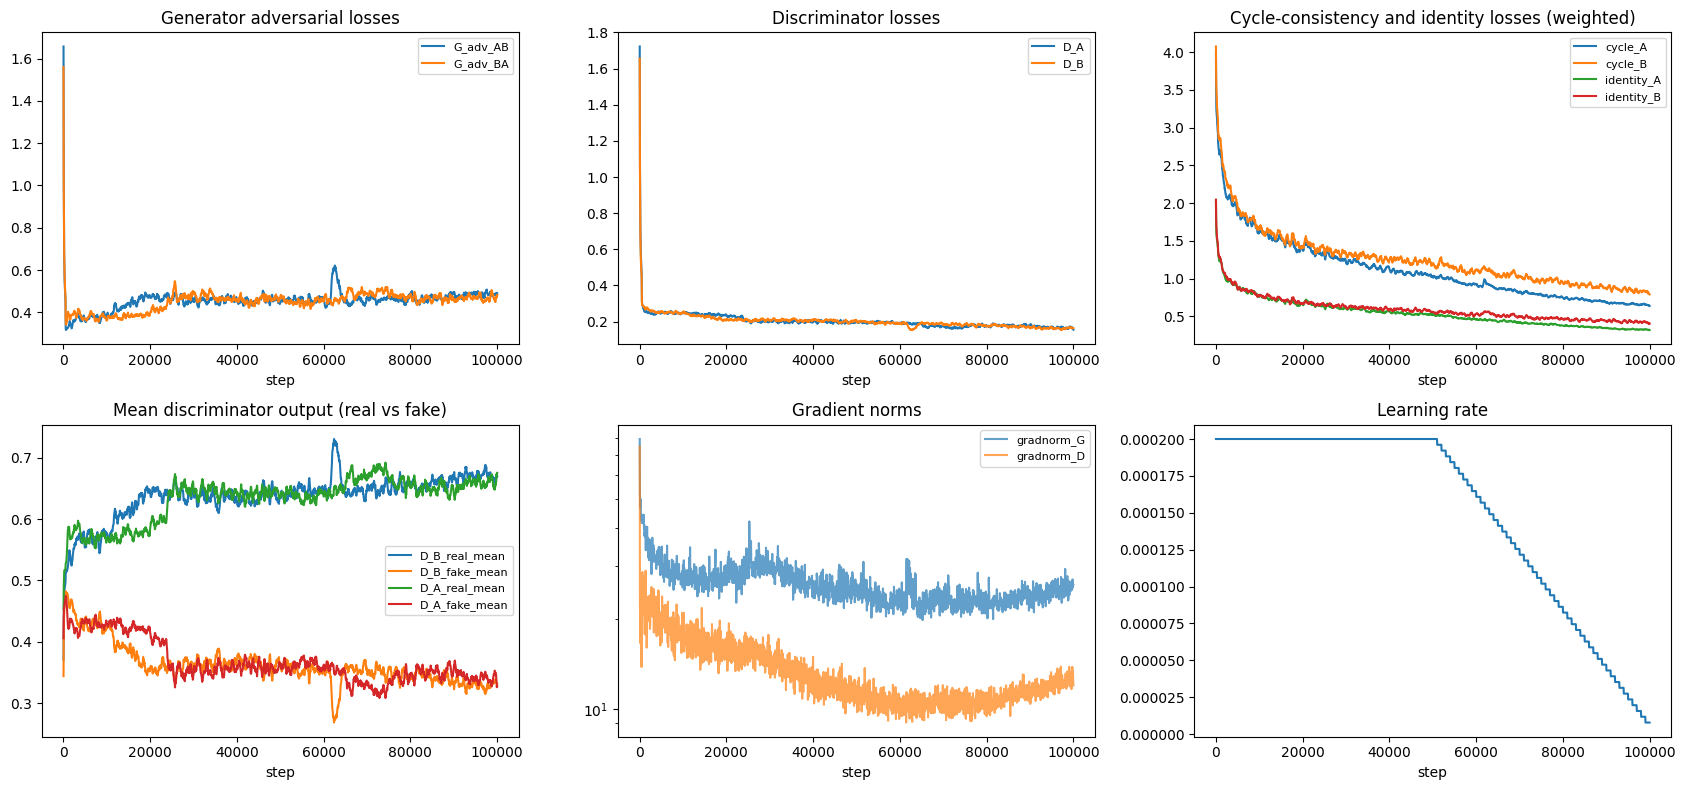

{
 "final_epoch_G_adv_AB": 0.4865965421199799,
 "final_epoch_G_adv_BA": 0.46619783758372063,
 "final_epoch_D_A": 0.16272721848264335,
 "final_epoch_D_B": 0.1657583411410451,
 "final_epoch_cycle_loss_A": 0.6448473275601866,
 "final_epoch_cycle_loss_B": 0.8123353006541729,
 "final_epoch_identity_loss_A": 0.32051951417326924,
 "final_epoch_identity_loss_B": 0.41250118912756434,
 "gradnorm_G_mean": 25.93441289412265,
 "gradnorm_G_max": 79.22019114392869,
 "gradnorm_D_mean": 13.227890989874883,
 "gradnorm_D_max": 74.70412680443297,
 "gradnorm_G_nonfinite_steps": 41,
 "gradnorm_D_nonfinite_steps": 3,
 "nan_count": 0,
 "amp_overflow_skips": 42,
 "training_time_min": 249.93821595453312,
 "train_steps": 100000,
 "epochs": 100,
 "train_image_pairs_per_sec": 6.668314648488385,
 "peak_memory_mb": 1621.92822265625,
 "hardware": "NVIDIA GeForce RTX 5090 / Intel(R) Core(TM) Ultra 9 285K"
}


In [7]:
L = pd.DataFrame(state["log"])
L.to_csv(OUT_ROOT / "outputs" / "loss_log.csv", index=False)
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
sm = lambda s: s.rolling(10, min_periods=1).mean()
for k in ["G_adv_AB", "G_adv_BA"]: ax[0, 0].plot(L.step, sm(L[k]), label=k)
ax[0, 0].set_title("Generator adversarial losses")
for k in ["D_A", "D_B"]: ax[0, 1].plot(L.step, sm(L[k]), label=k)
ax[0, 1].set_title("Discriminator losses")
for k in ["cycle_A", "cycle_B", "identity_A", "identity_B"]: ax[0, 2].plot(L.step, sm(L[k]), label=k)
ax[0, 2].set_title("Cycle-consistency and identity losses (weighted)")
for k in ["D_B_real_mean", "D_B_fake_mean", "D_A_real_mean", "D_A_fake_mean"]: ax[1, 0].plot(L.step, sm(L[k]), label=k)
ax[1, 0].set_title("Mean discriminator output (real vs fake)")
for k in ["gradnorm_G", "gradnorm_D"]: ax[1, 1].plot(L.step, L[k], alpha=0.7, label=k)
ax[1, 1].set_yscale("log"); ax[1, 1].set_title("Gradient norms")
ax[1, 2].plot(L.step, L.lr); ax[1, 2].set_title("Learning rate")
for a in ax.flat:
    a.set_xlabel("step"); a.legend(fontsize=8) if a.get_legend_handles_labels()[0] else None
plt.tight_layout(); plt.savefig(OUT_ROOT / "outputs" / "loss_curves.png", dpi=120); plt.show()

last = L[L.epoch == L.epoch.max()]
TRAIN_SUMMARY = {
    "final_epoch_G_adv_AB": last.G_adv_AB.mean(), "final_epoch_G_adv_BA": last.G_adv_BA.mean(),
    "final_epoch_D_A": last.D_A.mean(), "final_epoch_D_B": last.D_B.mean(),
    "final_epoch_cycle_loss_A": last.cycle_A.mean(), "final_epoch_cycle_loss_B": last.cycle_B.mean(),
    "final_epoch_identity_loss_A": last.identity_A.mean(), "final_epoch_identity_loss_B": last.identity_B.mean(),
    "gradnorm_G_mean": L.gradnorm_G.mean(), "gradnorm_G_max": L.gradnorm_G.max(),
    "gradnorm_D_mean": L.gradnorm_D.mean(), "gradnorm_D_max": L.gradnorm_D.max(),
    "gradnorm_G_nonfinite_steps": state.get("gn_nonfinite_G", 0), "gradnorm_D_nonfinite_steps": state.get("gn_nonfinite_D", 0),
    "nan_count": state["nan_count"], "amp_overflow_skips": state["amp_skips"],
    "training_time_min": state["train_seconds"] / 60, "train_steps": state["step"], "epochs": state["epoch"],
    "train_image_pairs_per_sec": state["step"] * bs / max(state["train_seconds"], 1e-9),
    "peak_memory_mb": PEAK_MB, "hardware": f"{HW.get('gpu')} / {HW['cpu']}",
}
TRAIN_SUMMARY = {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in TRAIN_SUMMARY.items()}
print(json.dumps(TRAIN_SUMMARY, indent=1))

In [8]:
# final checkpoint: all four networks in fp16 (small enough for GitHub), plus config and training summary
CK_FINAL = OUT_ROOT / "checkpoints" / "cyclegan_final.pt"
torch.save({"G_AB": {k: v.half() for k, v in G_AB.state_dict().items()},
            "G_BA": {k: v.half() for k, v in G_BA.state_dict().items()},
            "D_A": {k: v.half() for k, v in D_A.state_dict().items()},
            "D_B": {k: v.half() for k, v in D_B.state_dict().items()},
            "config": CFG, "train_summary": TRAIN_SUMMARY}, CK_FINAL)
CKPT_ID = file_sha(CK_FINAL)
log(f"saved {CK_FINAL.name} ({CK_FINAL.stat().st_size / 1e6:.1f} MB), checkpoint ID {CKPT_ID}")

saved cyclegan_final.pt (56.6 MB), checkpoint ID 9fd12c2b6237


## Evaluation (shared metrics, both directions)
`evaluate_local.py` is run in-process (the same code a grader can run from the command line).
It reloads the **fp16 final checkpoint**, so the metrics describe exactly the weights that are committed.
Outputs: `full_metrics_report.csv`, `outputs/pred_A2B/` (300 generated photos, one per Monet),
`outputs/pred_B2A/` (500 generated Monets, one per held-out photo), `outputs/audit/` (30 fixed photos → Monet),
and cycle-consistency figures in `outputs/figures/`.

In [9]:
ck, gAB, gBA, dA, dB = EV.load_final(CK_FINAL, device)
REPORT = EV.run_evaluation(CFG, gAB, gBA, dA, dB, TRAIN_SUMMARY, device, OUT_ROOT, log=log, seed=SEED)
wide = REPORT[REPORT.direction != "both"].pivot(index="metric", columns="direction", values="value")
print(wide.round(4).to_string())

evaluating on 300 Monet paintings (A) and 500 held-out photos (B, team split)
                     metric direction                                                    value
               n_translated       A2B                                                      300
           n_real_reference       A2B                                                      500
                        fid       A2B                                               106.058592
                   kid_mean       A2B                                                 0.035624
                    kid_std       A2B                                                   0.0034
              gen_precision       A2B                                                 0.516667
                 gen_recall       A2B                                                    0.516
                gen_density       A2B                                                 0.415333
               gen_coverage       A2B                              

### Verifying cycle consistency
If the cycle constraint is implemented correctly, **cycle L1 (input vs reconstruction) is much smaller
than L1 (input vs translation)**: the translation changes the image, and the other generator undoes the change.
The figures below show input / translation / reconstruction, plus the images with the worst reconstruction.

A2B: cycle L1 0.0761 vs input-translation L1 0.1894 -> cycle constraint VERIFIED
B2A: cycle L1 0.0985 vs input-translation L1 0.3024 -> cycle constraint VERIFIED


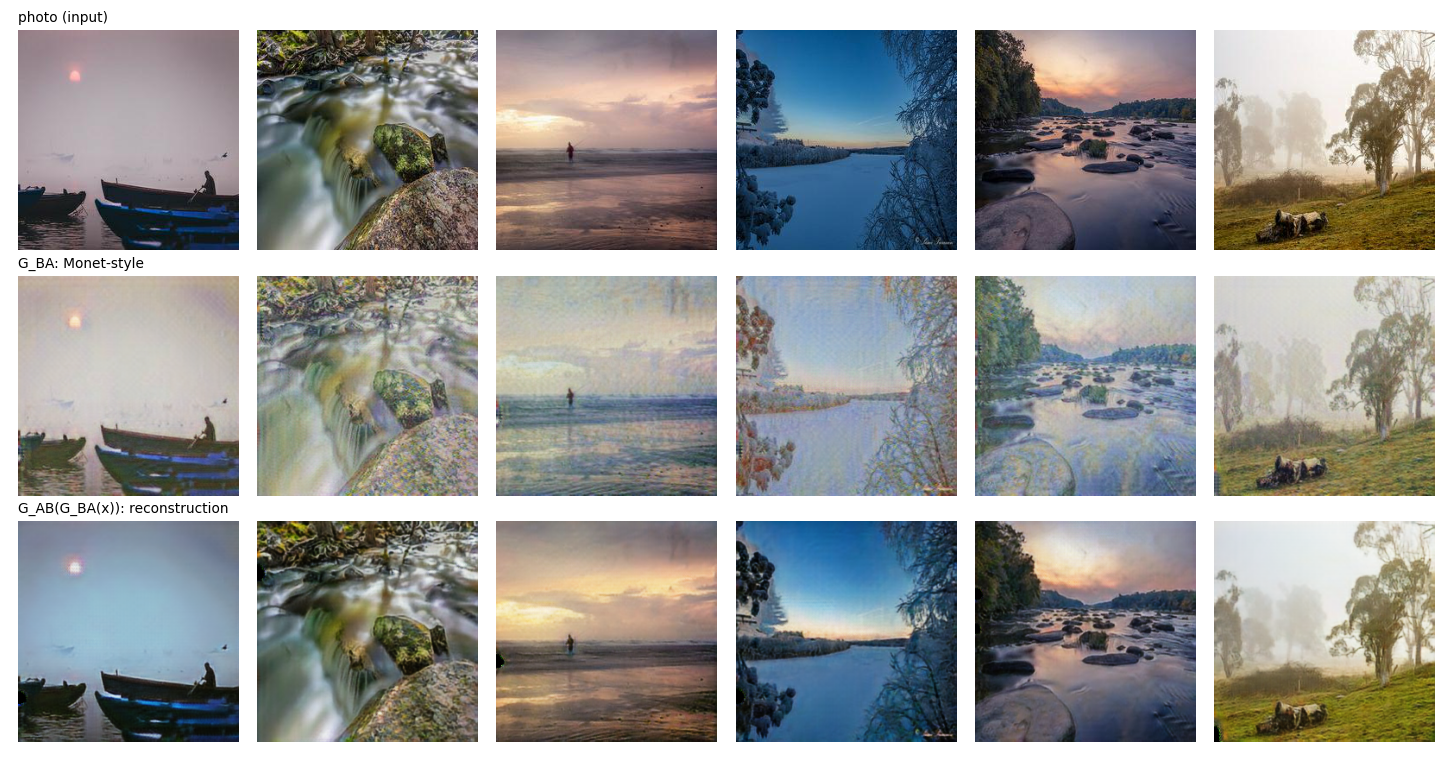

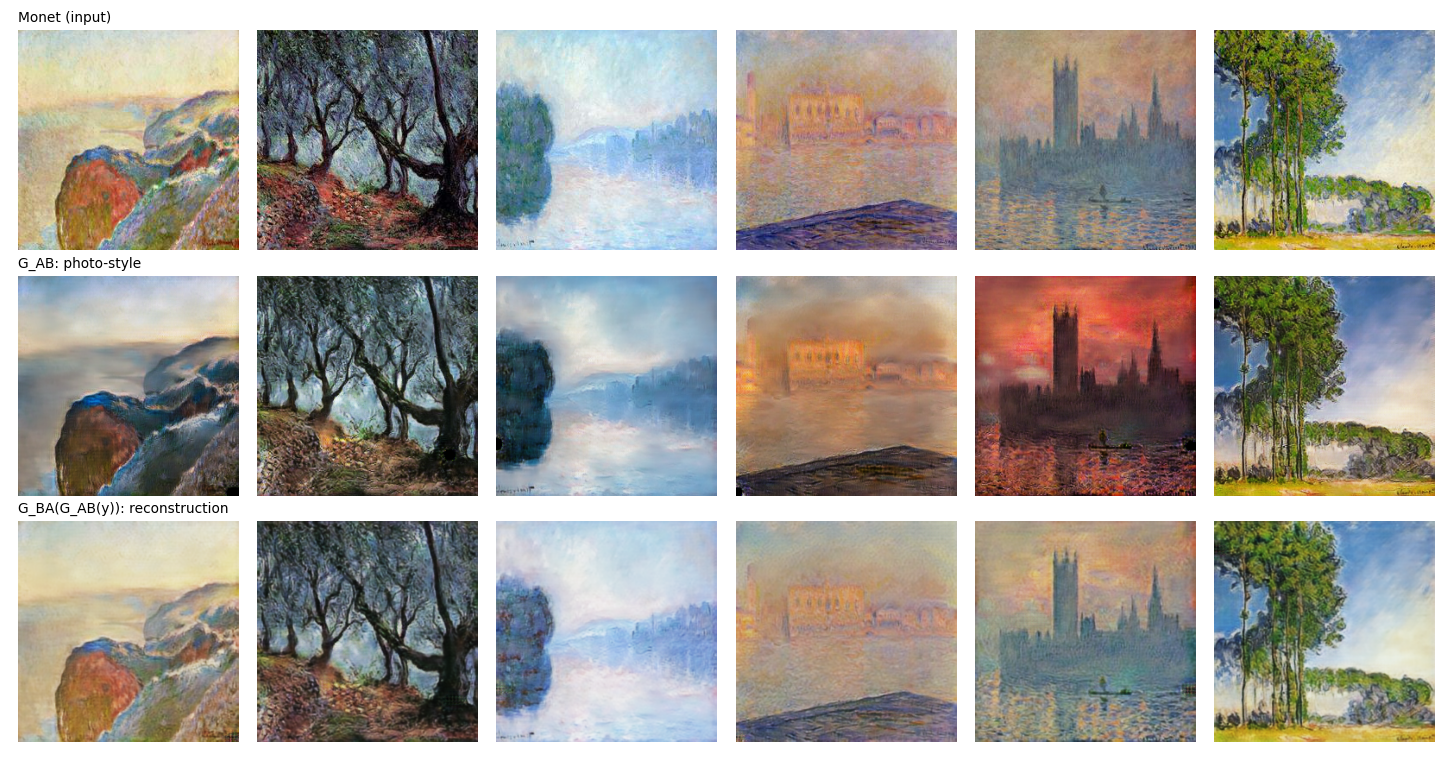

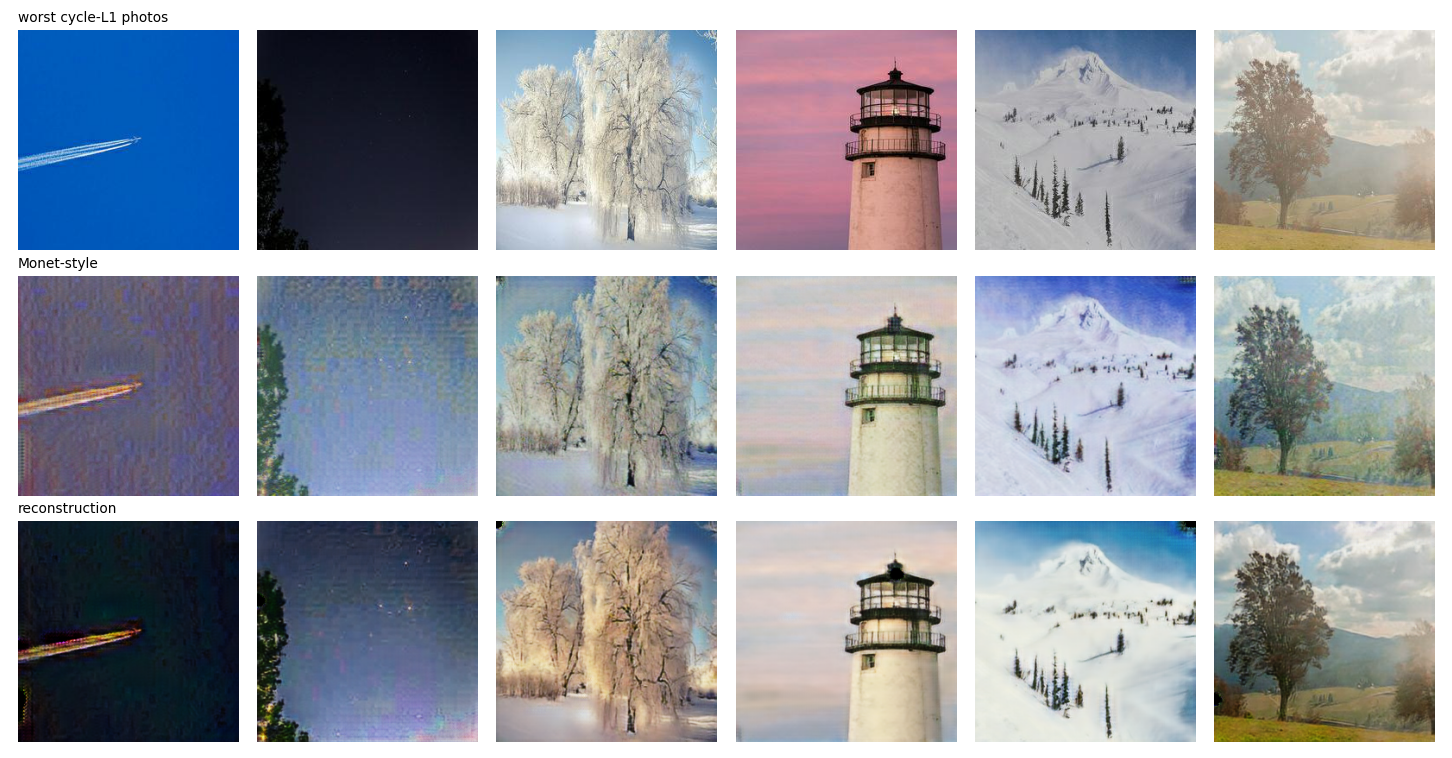

In [10]:
for d in ["A2B", "B2A"]:
    r = REPORT[(REPORT.direction == d)].set_index("metric")["value"]
    ok = r["cycle_l1"] < r["l1_input_vs_translation"]
    log(f"{d}: cycle L1 {r['cycle_l1']:.4f} vs input-translation L1 {r['l1_input_vs_translation']:.4f} -> cycle constraint {'VERIFIED' if ok else 'NOT satisfied'}")
from IPython.display import Image as _Img, display
for f in ["cycle_B2A_photo2monet.png", "cycle_A2B_monet2photo.png", "worst_cycle_B2A.png"]:
    display(_Img(filename=str(OUT_ROOT / "outputs" / "figures" / f)))

## Kaggle `submission.csv` — computed by the course's official evaluation script
The ISA's `Part3_Evaluation_Script.ipynb` (copied **unchanged** into `task3_gan/common/`) is executed on this
member's `pred_A2B/` and `pred_B2A/` folders. It writes `submission.csv` (ID, FID, MiFID = average of both
directions), which is copied to `task3_gan/<member>/submission.csv`. Upload **that file** to Kaggle, from
the account of the member who owns this model, then record the score and rank in `config.yaml → kaggle`.

In [11]:
if not is_smoke():
    SUB = EV.official_submission(CFG, OUT_ROOT, log=log)
    print(SUB)

running the official evaluation script (unchanged) ...


[NbConvertApp] Converting notebook Part3_Evaluation_Script.ipynb to notebook


official submission.csv: [{'ID': 1, 'FID': 108.99209502942269, 'MiFID': 0.4188115166031037}]  -> /app/data266-lab1/task3_gan/ruchika_chaurasia/runs/long100_diffaug/submission.csv
   ID         FID     MiFID
0   1  108.992095  0.418812


[NbConvertApp] Writing 14928 bytes to official_eval_executed.ipynb


## results.md + manifest
Fill in the Kaggle score/rank (in `config.yaml → kaggle`) and the human-audit results (from
`task3_gan/audit/score_audit.py`), then re-run **only this cell** to refresh `results.md`.

In [12]:
CFG_NOW = load_config(CFG_PATH)
kg = CFG_NOW.get("kaggle", {})
audit_csv = REPO_ROOT / "task3_gan" / "audit" / "audit_results.csv"
audit_txt = pd.read_csv(audit_csv).to_markdown(index=False) if audit_csv.exists() and importlib.util.find_spec("tabulate") else \
    ("see task3_gan/audit/audit_results.csv" if audit_csv.exists() else "TODO — run the blinded audit (task3_gan/audit/README.md)")

def md(df):
    out = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(f"{v:.4g}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + " |")
    return "\n".join(out)

arch = (f"Generators: {MC['generator']} (ngf {MC['ngf']}" + (f", {MC.get('n_res_blocks')} residual blocks" if MC["generator"] == "resnet" else ", 8-level U-Net with skips")
        + f"); discriminators: PatchGAN ndf {MC['ndf']}, {MC.get('d_layers', 3)} stride-2 layers; instance norm.")
hp = (f"GAN loss {TC['gan_loss']}, λ_cycle {lam_c}, λ_identity {lam_i} (×λ_cycle), Adam lr {TC['lr']} β1 {TC['beta1']}, "
      f"batch {bs}, {TC['epochs']} epochs × {TC['steps_per_epoch']} steps (linear decay from epoch {TC['decay_start_epoch']}), "
      f"image pool {TC['pool_size']}, AMP {USE_AMP}, DiffAugment {POLICY or 'none'}, image {dc['image_size']} "
      f"(load {dc['load_size']}, random crop + flip), seed {SEED}")
both = REPORT[REPORT.direction == "both"][["metric", "value"]]
results = f"""# Task 3 — CycleGAN photo↔Monet · {MEMBER} (lineup {CFG.get('lineup')}, run: {RUN or 'main'})

## What I built
{arch}

**Hyper-parameters:** {hp}.

## Why (design justification)
{CFG.get('rationale', 'TODO')}

## Metrics — both directions (checkpoint `{CKPT_ID}`)
{md(wide.round(4).reset_index())}

## Training, stability and cost
{md(both)}

## Kaggle
Public score: {kg.get('public_score', 'TODO')} · private score: {kg.get('private_score', 'TODO')} · team rank: {kg.get('rank', 'TODO')}
(`submission.csv` from the official script on this member's `pred_A2B/` + `pred_B2A/`, checkpoint `{CKPT_ID}`).

## Human audit (30 fixed photos, 2 blinded raters)
{audit_txt}

## Training behaviour (write in your own words)
TODO — describe the loss curves (`outputs/loss_curves.png`) and progress grids (`outputs/progress/`):
did cycle loss plateau, did D overpower G, any spikes/NaNs, when did Monet-like texture appear?

## Evidence
Loss log `outputs/loss_log.csv` · curves `outputs/loss_curves.png` · progress grids `outputs/progress/` ·
cycle figures `outputs/figures/` · predictions `outputs/pred_A2B/`, `outputs/pred_B2A/` · raw log `{log.path.relative_to(REPO_ROOT)}`.

## Hardware
{json.dumps(HW)}
"""
(OUT_ROOT / "results.md").write_text(results, encoding="utf-8")
man = write_manifest(REPO_ROOT, TASK, TAG, CFG, {"cyclegan_final": CK_FINAL},
                     [OUT_ROOT / "full_metrics_report.csv", OUT_ROOT / "results.md"], extra={"raw_log": str(log.path.relative_to(REPO_ROOT))})
log("wrote results.md and manifest:", man.relative_to(REPO_ROOT))

wrote results.md and manifest: reproducibility/manifests/task3_gan_ruchika_chaurasia_long100_diffaug_20261002_052647.json
